2D-plot of axion-signal: Amplitude, relative phase—-Fix omega

In [2]:
import numpy as np
import sys,os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils import libanaly
import matplotlib.pyplot as plt

import matplotlib.ticker as ticker

In [3]:
EVPA_fit_result=np.load("../GRMHD/EVPA_fit_result.npy")

In [4]:
plt.rcParams['font.family'] ='Times New Roman'
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'  # 设置正常文本的字体
plt.rcParams['mathtext.it'] = 'Times New Roman:italic'  # 设置斜体文本的字体
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'  # 设置粗体文本的字体

In [5]:
def Plot_Background(fig, ax, array2d,size=20):
    shape = array2d.shape[0]
    xgrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    ygrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    diff = np.diff(xgrid)[0] / 2.0
    xgrid += diff
    ygrid += diff
    xmesh, ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")

    bkg = ax.pcolormesh(
        xmesh, ymesh, array2d / np.nanmax(array2d), cmap="hot", vmin=0, vmax=1, shading="auto"
    )
    ax.set_aspect("equal")
    clb = fig.colorbar(bkg, ax=ax, fraction=0.046, pad=0.05)
    clb.ax.tick_params(labelsize=size)
    clb.set_label("$I/I_{max}$", labelpad=-40, y=1.05, rotation=0, size=size)

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def Plot_Background_NoNorm(fig, ax, array2d,
                           xy_labelsize=28,
                           xy_tick_labelsize=14,
                           cbar_tick_labelsize=12,
                           cbar_label=False,
                           cbar_label_fontsize=16,
                           cbar_label_pad=20,
                           cbar_label_y=0.5,
                           cbar_label_rotation=0,
                           cbar_label_text="Value", # Colorbar 标签文本
                           data_vmin=None,          # 颜色映射的最小值 (None则自动)
                           data_vmax=None,cmap="Greys_r"):         # 颜色映射的最大值 (None则自动)
    """
    绘制背景图，不进行数据归一化，并调整坐标轴和Colorbar的样式。

    参数:
    - fig: matplotlib Figure 对象
    - ax: matplotlib Axes 对象
    - array2d: 二维数组数据 (原始值)
    - xy_tick_labelsize: XY轴刻度数字的字号
    - cbar_tick_labelsize: Colorbar刻度数字的字号
    - cbar_label_fontsize: Colorbar标签的字号
    - cbar_label_pad: Colorbar标签与Colorbar之间的距离 (points)
    - cbar_label_y: Colorbar标签的相对垂直位置 (0.0-1.0, 0.5表示中间)
    - cbar_label_rotation: Colorbar标签的旋转角度
    - cbar_label_text: Colorbar的标签文本
    - data_vmin: pcolormesh的vmin参数 (None则自动确定)
    - data_vmax: pcolormesh的vmax参数 (None则自动确定)
    """
    
    
    
    shape = array2d.shape[0]
    xgrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    ygrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    diff = np.diff(xgrid)[0] / 2.0
    xgrid += diff
    ygrid += diff
    xmesh, ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")

    # 数据不再进行归一化

    bkg = ax.pcolormesh(
        xmesh, ymesh, array2d,  # 使用原始 array2d
        cmap=cmap,
        vmin=data_vmin,         # 使用新的 vmin 参数
        vmax=data_vmax,         # 使用新的 vmax 参数
        shading="auto"
    )
    ax.set_aspect("equal")
    ax.set_xlabel(r"$r/r_g$",fontsize=xy_labelsize)
    ax.set_ylabel(r"$r/r_g$", fontsize=xy_labelsize)

    # 1. 调整XY轴刻度标签大小
    ax.tick_params(axis='x', labelsize=xy_tick_labelsize)
    ax.tick_params(axis='y', labelsize=xy_tick_labelsize)

    # 添加Colorbar
    clb = fig.colorbar(bkg, ax=ax, fraction=0.046, pad=0.05)

    # 2. 调整Colorbar刻度标签大小
    clb.ax.tick_params(labelsize=cbar_tick_labelsize)

    # 3. 调整Colorbar标签的属性
    if cbar_label:
        clb.set_label(cbar_label_text,  # 使用新的 cbar_label_text 参数
                  labelpad=cbar_label_pad,
                  y=cbar_label_y,
                  rotation=cbar_label_rotation,
                  size=cbar_label_fontsize)
    
    return bkg, clb




最亮部分差别小一些的colorbar？

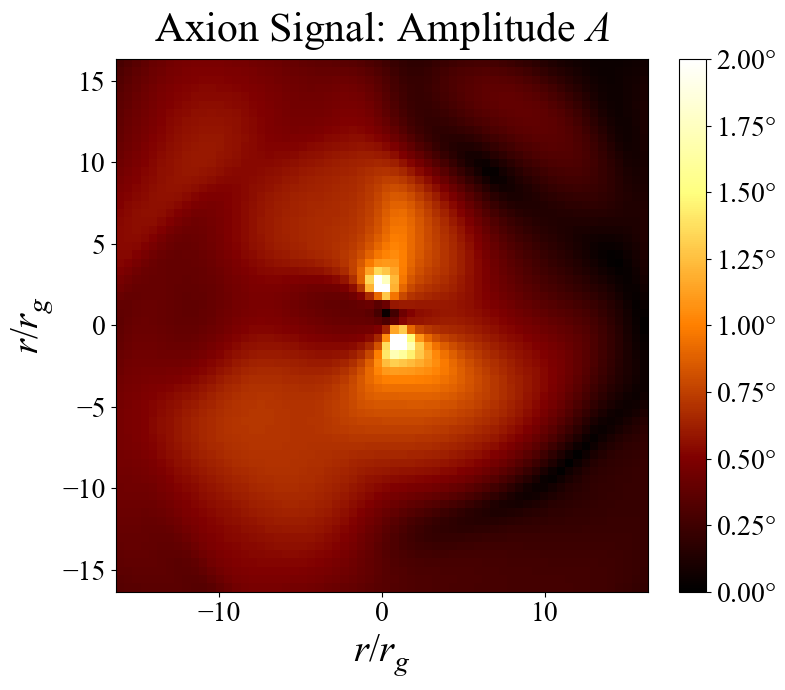

In [8]:

# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
_,clb=Plot_Background_NoNorm(fig, ax, EVPA_fit_result[30,:,:,0]/np.pi*180,
                        xy_tick_labelsize=20,
                        cbar_tick_labelsize=20,
                        cbar_label_fontsize=20,
                        cbar_label_pad=27,
                        cbar_label_y=0.5,
                        cbar_label_rotation=270,
                        cbar_label_text=r"Amplitude caused by Axion/$\degree$", # 自定义Colorbar标签
                        # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
                        # 或者您可以手动指定，例如:
                        data_vmin=0,
                        data_vmax=2,
                        cmap="afmhot",
                        )

clb.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter(r'$%.2f\degree$'))
# 添加主图的标题和轴标签（可选）
ax.set_title(r"Axion Signal: Amplitude $A$", fontsize=30,pad=13)

# 4. 自动调整布局
fig.tight_layout()
plt.savefig("images/Axion Signal/A.png")
# 5. 显示图像
plt.show()

# 颜色变化小一些
# 标题在上方
# 字体
# 视界大小的小黑圈？

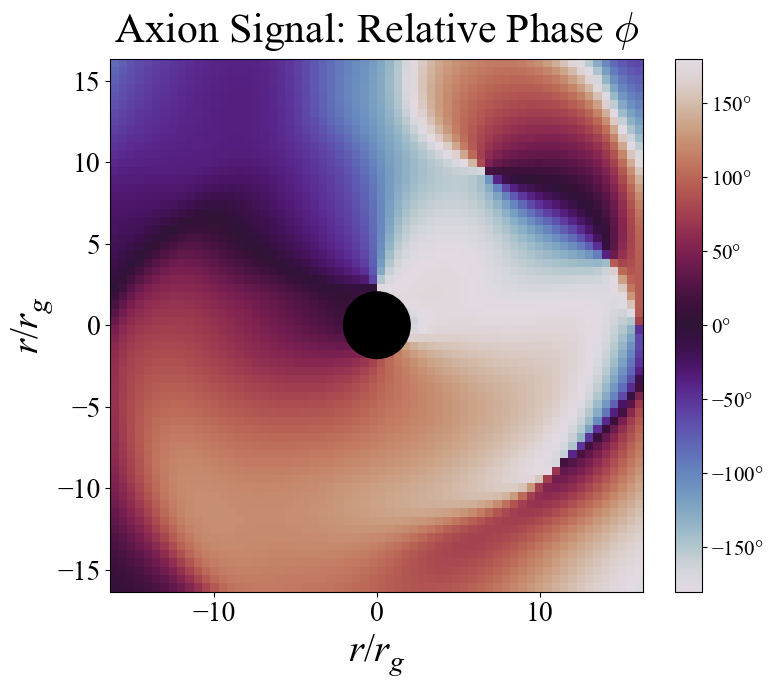

In [26]:
import cmocean.cm as cmo
# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
_,clb=Plot_Background_NoNorm(fig, ax, EVPA_fit_result[30,:,:,1]/np.pi*180,
                        xy_labelsize=28,
                        xy_tick_labelsize=20,
                        cbar_tick_labelsize=15,
                        cbar_label_fontsize=20,
                        cbar_label_pad=27,
                        cbar_label_y=0.5,
                        cbar_label_rotation=270,
                        cbar_label_text=r"Phase caused by Axion/$\degree$", # 自定义Colorbar标签
                        # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
                        # 或者您可以手动指定，例如:
                        # data_vmin=0,
                        # data_vmax=180,
                        # cmap=cmo.phase
                        cmap="twilight"  # 使用cmocean的twilight_r色图
                        )

clb.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter(r'$%.0f\degree$'))
# 添加主图的标题和轴标签（可选）
ax.set_title(r"Axion Signal: Relative Phase $\phi$", fontsize=30,pad=12)
ax.yaxis.set_label_coords(-0.1, 0.5)

x_center = (ax.get_xlim()[0] + ax.get_xlim()[1]) / 2
y_center = (ax.get_ylim()[0] + ax.get_ylim()[1]) / 2

# 创建一个黑色圆圈，半径2
circle = plt.Circle((x_center, y_center), radius=2, color='black', fill=True, linewidth=2)

# 添加圆圈到坐标轴
ax.add_patch(circle)

# 4. 自动调整布局
fig.tight_layout()
plt.savefig("images/Axion Signal/phi.png")
# 5. 显示图像
plt.show()

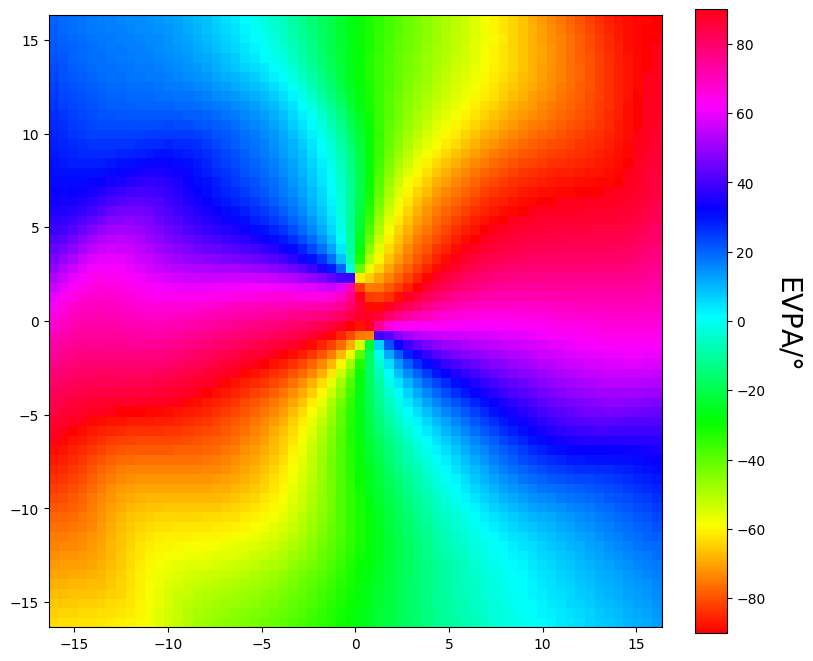

In [135]:

# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
Plot_Background_NoNorm(fig, ax, EVPA_fit_result[30,:,:,2]/np.pi*180,
                        xy_tick_labelsize=10,
                        cbar_tick_labelsize=10,
                        cbar_label_fontsize=20,
                        cbar_label_pad=27,
                        cbar_label_y=0.5,
                        cbar_label_rotation=270,
                        cbar_label_text=r"EVPA/$\degree$", # 自定义Colorbar标签
                        # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
                        # 或者您可以手动指定，例如:
                        # data_vmin=0,
                        # data_vmax=180
                        cmap="hsv"
                        )

# 添加主图的标题和轴标签（可选）
# ax.set_title("64x64 Data Visualization (No Normalization)", fontsize=16)

# 4. 自动调整布局
fig.tight_layout()
plt.savefig("fig2_evpa.png")
# 5. 显示图像
plt.show()

In [109]:
grmhdDataAfterImageS=np.load("../GRMHD/grmhdDataAfterImageS.npy")

In [110]:
grmhdDataAfterImageS[0,0,:,:,0]

(141, 17, 64, 64, 4)

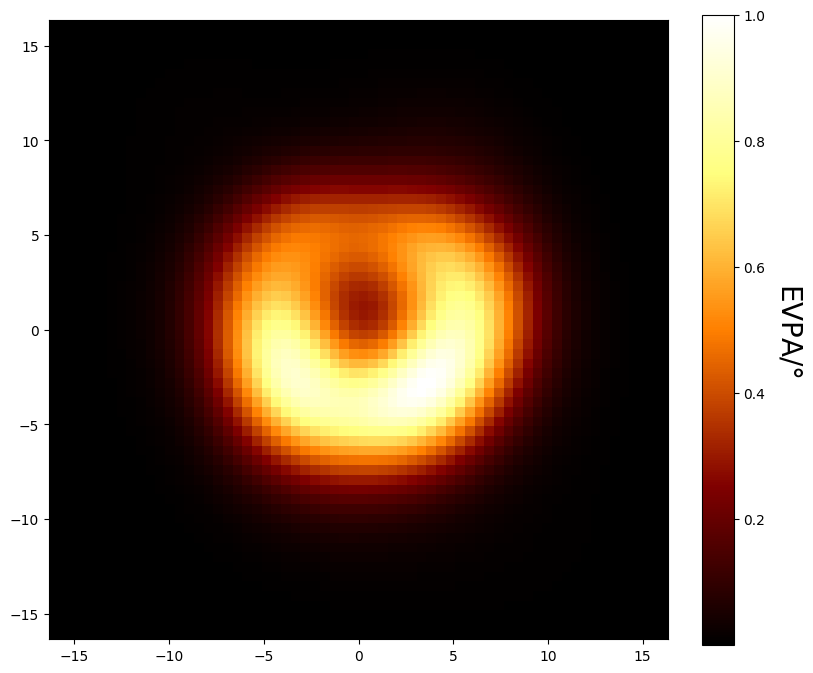

In [126]:

# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
Plot_Background_NoNorm(fig, ax, grmhdDataAfterImageS[30,0,:,:,0]/np.nanmax(grmhdDataAfterImageS[30,0,:,:,0]),
                        xy_tick_labelsize=10,
                        cbar_tick_labelsize=10,
                        cbar_label_fontsize=20,
                        cbar_label_pad=27,
                        cbar_label_y=0.5,
                        cbar_label_rotation=270,
                        cbar_label_text=r"EVPA/$\degree$", # 自定义Colorbar标签
                        # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
                        # 或者您可以手动指定，例如:
                        # data_vmin=0,
                        # data_vmax=180,
                        cmap="afmhot"
                        )

# 添加主图的标题和轴标签（可选）
# ax.set_title("64x64 Data Visualization (No Normalization)", fontsize=16)

# 4. 自动调整布局
fig.tight_layout()
plt.savefig("fig2_I.png")
# 5. 显示图像
plt.show()